# 01 · Exploração do dataset

Objetivo: entender o dataset antes de modelar e fechar, com dados, as pendências que dependem dele:

1. Quais arquivos do dataset usar?
2. Quais filas viram categorias, e se as pequenas serão agrupadas.
3. Como as prioridades se distribuem (o P1 é raro? o "alta" é raro?).
4. Que acerto um modelo simples alcança, e com qual cobertura, para orientar a meta que define o limiar de confiança.
5. Existem tickets "incompletos" de verdade, para o agente de esclarecimento?

Dados: [Tobi-Bueck/customer-support-tickets](https://huggingface.co/datasets/Tobi-Bueck/customer-support-tickets), baixados com `uv run python scripts/download_data.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from ticketflow.config import MAIN_FILE, RAW_DIR
from ticketflow.data.load import load_tickets

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 1. Quais arquivos usar

O repositório do Hugging Face tem três CSVs. O número "61.765 tickets" é a soma dos três, mas eles não são o mesmo dataset.

In [2]:
arquivos = {
    "v5 (multi-lang 5-2-50)": MAIN_FILE,
    "v4 (multi-lang 20k)": "dataset-tickets-multi-lang-4-20k.csv",
    "alemão normalizado": "dataset-tickets-german_normalized_50_5_2.csv",
}
brutos = {nome: pd.read_csv(RAW_DIR / f) for nome, f in arquivos.items()}
resumo = pd.DataFrame({
    nome: {
        "linhas": len(df),
        "colunas": df.shape[1],
        "filas distintas": df["queue"].nunique(),
        "prioridades": ", ".join(sorted(df["priority"].unique())),
        "idiomas": ", ".join(sorted(df["language"].unique())),
        "tem resposta do atendente": "answer" in df,
    }
    for nome, df in brutos.items()
}).T
print("Total somado:", resumo["linhas"].sum())
resumo

Total somado: 61765


,linhas,colunas,filas distintas,prioridades,idiomas,tem resposta do atendente
v5 (multi-lang 5-2-50),28587,16,10,"high, low, medium","de, en",True
v4 (multi-lang 20k),20000,15,10,"high, low, medium","de, en",True
alemão normalizado,13178,5,42,"critical, high, low, medium, very_low",de,False


In [3]:
v5, v4 = brutos["v5 (multi-lang 5-2-50)"], brutos["v4 (multi-lang 20k)"]
comuns = set(v5["body"]) & set(v4["body"])
print(f"Corpos idênticos entre v4 e v5: {len(comuns):,} ({len(comuns) / len(v4):.0%} da v4)")
print("Filas do alemão normalizado (amostra):", brutos["alemão normalizado"]["queue"].unique()[:6])

Corpos idênticos entre v4 e v5: 8,399 (42% da v4)
Filas do alemão normalizado (amostra): <ArrowStringArray>
[          'Food & Drink/Groceries',       'Books & Literature/Fiction',
        'Home & Garden/Landscaping', 'IT & Technology/Hardware Support',
                             'News',           'Shopping/Retail Stores']
Length: 6, dtype: str


**Leitura:**

- O arquivo **alemão normalizado** usa outra taxonomia (42 temas como *Pets & Animals/Pet Services*) e 5 prioridades. Não é compatível com as 10 filas de suporte.
- A **v4** é uma versão anterior da v5: boa parte dos tickets aparece nas duas. Juntar as duas criaria duplicatas, e uma duplicata que cai uma vez no treino e outra no teste infla a métrica (vazamento).
- **Decisão:** usar só a **v5**, com **28.587 tickets**. Daqui em diante o notebook usa `load_tickets()`, que lê a v5 e converte os `\n` literais do texto em quebras de linha reais.

In [4]:
df = load_tickets()
df["tamanho_corpo"] = df["body"].str.len()
print(df.shape)
df.head(3)

(28587, 10)


,subject,body,answer,type,queue,priority,language,version,tags,tamanho_corpo
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gegenwärtig mehrere Komp...",Vielen Dank für die Meldung des kritischen Sicherheitsvorfalls und die Bereitstellung der Übersicht über die betroff...,Incident,Technical Support,high,de,51,"[Security, Outage, Disruption, Data Breach]",747
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management ...","Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, ...",Incident,Technical Support,high,en,51,"[Account, Disruption, Outage, IT, Tech Support]",540
2,Query About Smart Home System Integration Features,"Dear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed informati...","Thank you for your inquiry. Our products support integration with Amazon Alexa, Google Assistant, and Apple HomeKit....",Request,Returns and Exchanges,medium,en,51,"[Product, Feature, Tech Support]",530


## 2. Qualidade dos dados

In [5]:
qualidade = pd.Series({
    "assunto vazio": (df["subject"] == "").mean(),
    "resposta ausente": df["answer"].isna().mean(),
    "corpos duplicados": df["body"].duplicated().mean(),
}).map("{:.1%}".format)
print(qualidade.to_string())
df["tamanho_corpo"].describe().round(0)

assunto vazio        13.4%
resposta ausente      0.0%
corpos duplicados     0.0%


count    28587.0
mean       387.0
std        200.0
min          6.0
25%        219.0
50%        386.0
75%        550.0
max       1463.0
Name: tamanho_corpo, dtype: float64

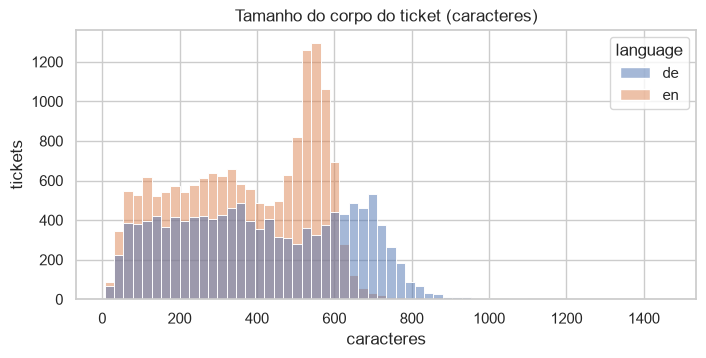

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(df, x="tamanho_corpo", hue="language", bins=60, ax=ax)
ax.set(title="Tamanho do corpo do ticket (caracteres)", xlabel="caracteres", ylabel="tickets")
plt.show()

## 3. Filas (candidatas a categoria)

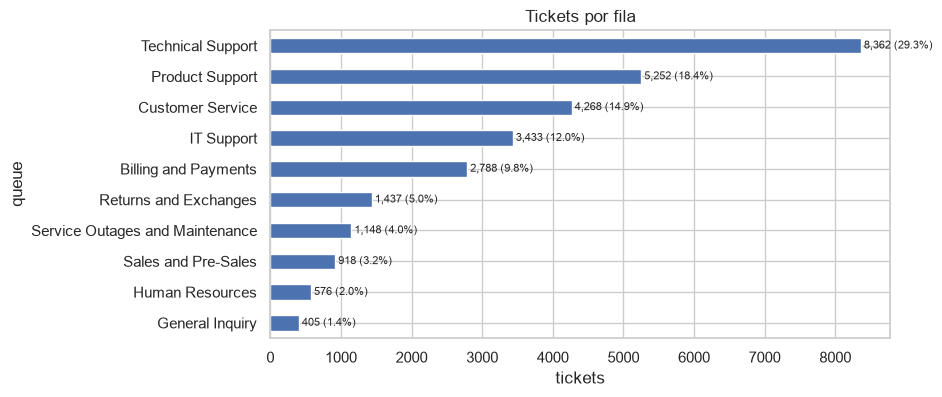

In [7]:
filas = df["queue"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
filas.sort_values().plot.barh(ax=ax)
ax.set(title="Tickets por fila", xlabel="tickets")
for i, v in enumerate(filas.sort_values()):
    ax.text(v, i, f" {v:,} ({v / len(df):.1%})", va="center", fontsize=8)
plt.show()

## 4. Prioridade

priority
medium    40.3%
high      39.1%
low       20.6%


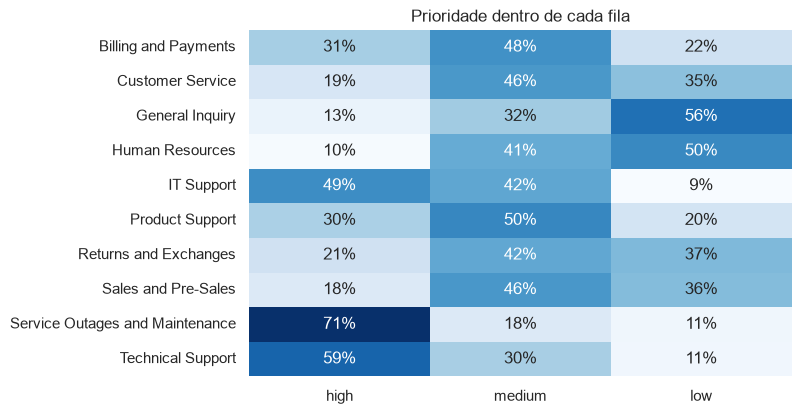

In [8]:
print(df["priority"].value_counts(normalize=True).map("{:.1%}".format).to_string())
ct = pd.crosstab(df["queue"], df["priority"], normalize="index")[["high", "medium", "low"]]
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Prioridade dentro de cada fila", xlabel="", ylabel="")
plt.show()

## 5. Idioma, tipo e tags

In [9]:
print(pd.crosstab(df["queue"], df["language"], normalize="index").map("{:.0%}".format))
print()
print(df["type"].value_counts().to_string())

language                          de   en
queue                                    
Billing and Payments             43%  57%
Customer Service                 44%  56%
General Inquiry                  42%  58%
Human Resources                  40%  60%
IT Support                       43%  57%
Product Support                  41%  59%
Returns and Exchanges            43%  57%
Sales and Pre-Sales              44%  56%
Service Outages and Maintenance  42%  58%
Technical Support                43%  57%

type
Incident    11466
Request      8187
Problem      6012
Change       2922


In [10]:
tags = df["tags"].explode()
print("Tags distintas:", tags.nunique())
print("Tickets cuja lista de tags contém o nome da própria fila:",
      f"{df.apply(lambda r: r['queue'] in r['tags'], axis=1).mean():.1%}")
tags.value_counts().head(15)

Tags distintas: 1255


Tickets cuja lista de tags contém o nome da própria fila: 0.3%


tags
Tech Support     16505
IT               16325
Performance      13374
Feedback          7937
Bug               7492
Security          7046
Feature           6660
Documentation     6167
Disruption        5744
Outage            4364
Network           3693
Product           2503
Recovery          2494
Sales             2432
Hardware          1569
Name: count, dtype: int64

**Atenção ao vazamento:** `type`, `tags` e `answer` são preenchidos pelo atendente **depois** da triagem. Num ticket que acabou de chegar eles não existem, então **não podem ser features** do classificador. O modelo usa só `subject` + `body` (e o idioma, que é detectável do texto). A `answer` serve para outra coisa: é a base de conhecimento do agente de resolução (RAG).

## 6. Quão separáveis são as filas? (checagem rápida, não é o modelo final)

Um TF-IDF + regressão logística, com divisão estratificada 80/20, só para saber a ordem de grandeza do acerto e,
principalmente, **quanto dá para automatizar** em cada meta de acerto. Isso alimenta a pendência do limiar de confiança.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

texto = df["subject"] + "\n" + df["body"]


def checagem(alvo: pd.Series):
    x_tr, x_te, y_tr, y_te = train_test_split(texto, alvo, test_size=0.2, stratify=alvo, random_state=42)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    clf = LogisticRegression(max_iter=2000, C=5).fit(vec.fit_transform(x_tr), y_tr)
    proba = clf.predict_proba(vec.transform(x_te))
    pred = clf.classes_[proba.argmax(1)]
    return y_te.to_numpy(), pred, proba.max(1), clf.classes_


def curva_cobertura(y, pred, conf):
    linhas = []
    for limiar in np.arange(0.3, 0.96, 0.05):
        sel = conf >= limiar
        linhas.append({"limiar": round(limiar, 2), "cobertura": sel.mean(), "acerto": (pred[sel] == y[sel]).mean()})
    return pd.DataFrame(linhas)


resultados = {}
for nome, alvo in {"fila": df["queue"], "prioridade": df["priority"]}.items():
    y, pred, conf, classes = checagem(alvo)
    resultados[nome] = (y, pred, conf, classes)
    print(f"{nome:<10} acurácia {accuracy_score(y, pred):.3f} · F1 macro {f1_score(y, pred, average='macro'):.3f}")

fila       acurácia 0.592 · F1 macro 0.526


prioridade acurácia 0.648 · F1 macro 0.624


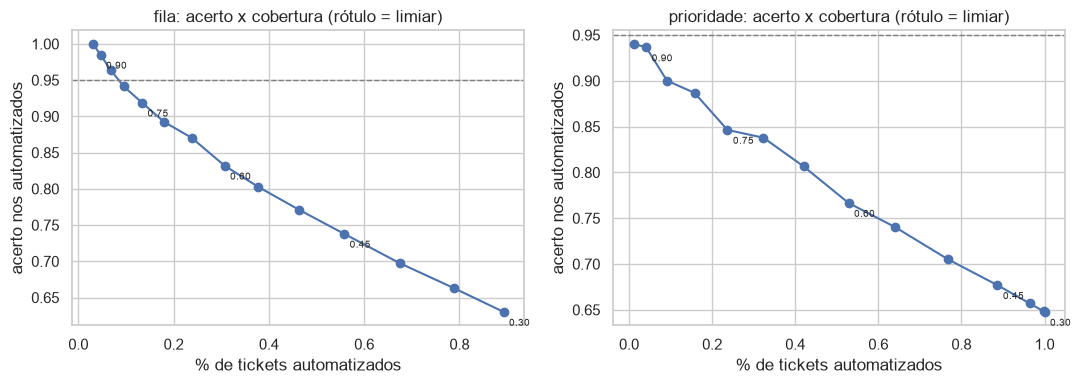

,limiar,cobertura,acerto
0,0.30,0.892,0.630
1,0.35,0.789,0.663
2,0.40,0.675,0.697
3,0.45,0.558,0.738
4,0.50,0.463,0.771
5,0.55,0.378,0.803
6,0.60,0.307,0.832
7,0.65,0.238,0.870
8,0.70,0.180,0.892
9,0.75,0.134,0.919


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, (y, pred, conf, _)) in zip(axes, resultados.items()):
    c = curva_cobertura(y, pred, conf)
    ax.plot(c["cobertura"], c["acerto"], marker="o")
    for _, r in c.iloc[::3].iterrows():
        ax.annotate(f"{r['limiar']:.2f}", (r["cobertura"], r["acerto"]), fontsize=7, xytext=(4, -10), textcoords="offset points")
    ax.axhline(0.95, ls="--", color="gray", lw=1)
    ax.set(title=f"{nome}: acerto x cobertura (rótulo = limiar)", xlabel="% de tickets automatizados", ylabel="acerto nos automatizados")
plt.tight_layout()
plt.show()
curva_cobertura(*resultados["fila"][:3]).round(3)

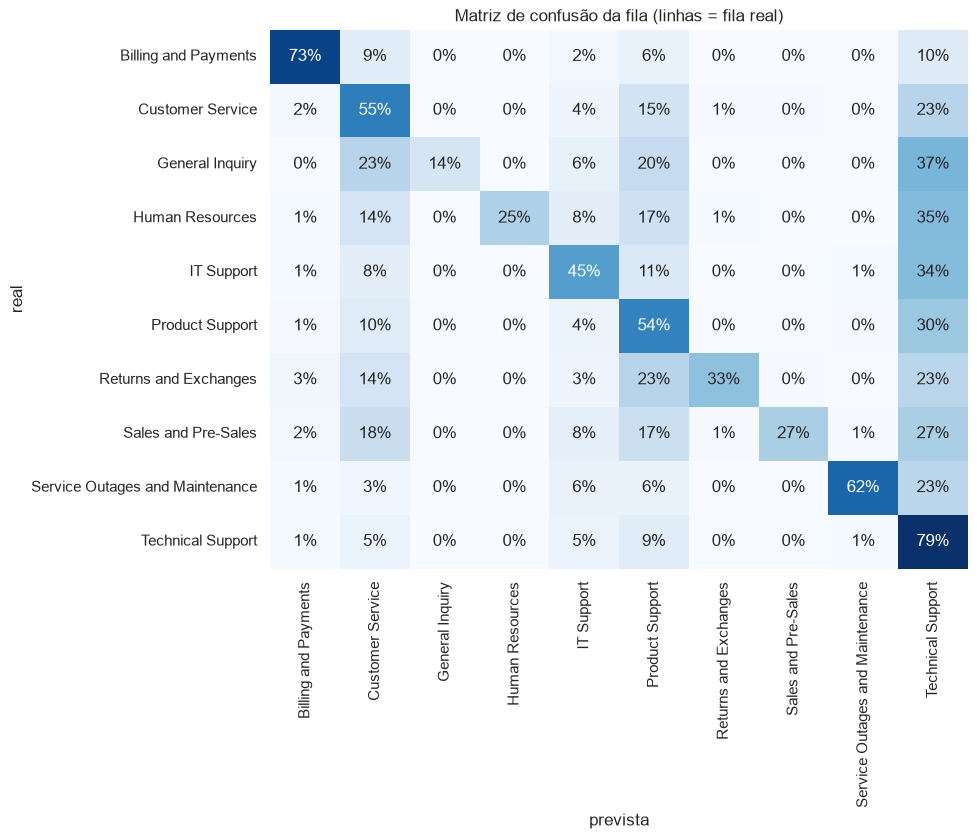

In [13]:
y, pred, conf, classes = resultados["fila"]
cm = pd.DataFrame(confusion_matrix(y, pred, labels=classes, normalize="true"), index=classes, columns=classes)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Matriz de confusão da fila (linhas = fila real)", xlabel="prevista", ylabel="real")
plt.show()

### Teste: agrupar as filas de suporte técnico ajuda?

Se as filas *Technical Support*, *Product Support* e *IT Support* se confundem entre si, agrupá-las mostraria um salto de acerto.

In [14]:
grupo = {"Technical Support": "Suporte técnico", "Product Support": "Suporte técnico", "IT Support": "Suporte técnico"}
fila_agrupada = df["queue"].replace(grupo)
y, pred, conf, _ = checagem(fila_agrupada)
print(f"fila agrupada: {fila_agrupada.nunique()} classes · acurácia {accuracy_score(y, pred):.3f} · F1 macro {f1_score(y, pred, average='macro'):.3f}")
curva_cobertura(y, pred, conf).round(3)

fila agrupada: 8 classes · acurácia 0.738 · F1 macro 0.485


,limiar,cobertura,acerto
0,0.30,0.991,0.743
1,0.35,0.972,0.751
2,0.40,0.937,0.764
3,0.45,0.890,0.780
4,0.50,0.834,0.802
5,0.55,0.773,0.821
6,0.60,0.712,0.838
7,0.65,0.641,0.859
8,0.70,0.573,0.876
9,0.75,0.504,0.891


## 7. Tickets curtos: candidatos a "incompleto"

In [15]:
curtos = df[df["tamanho_corpo"] < 60]
print(f"Corpos com menos de 60 caracteres: {len(curtos):,} ({len(curtos) / len(df):.1%})")
curtos[["subject", "body", "queue"]].sample(10, random_state=0)

Corpos com menos de 60 caracteres: 904 (3.2%)


,subject,body,queue
10179,Issue with accessing Discord server,description of the problem,IT Support
15349,,Möchten mehr Details zur digitalen Strategie erhalten?,Technical Support
16434,Problems with Several Integrations Today,Integrations are failing due to recent API changes.,IT Support
16125,Insights on Integrating TYPO3 SAP ERP,Seeking insights on integrating TYPO3 SAP ERP,Technical Support
6242,Update of Investment Data Analysis,Enhance analysis algorithms and improve data quality,Product Support
10617,Problem with Data Integration,The data analytics platform has encountered a failure.,Sales and Pre-Sales
2797,Fehler bei Investment Insights,Das Unternehmen hat ungenaue Renditeangaben erhalten.,Returns and Exchanges
28314,Netgear Nighthawk Mesh Wi-Fi 6 System Details,Could you provide more information on digital strategies?,Customer Service
4330,Regular Service Interruptions During Busy Hours,Regular service interruptions occur during peak times.,Technical Support
1270,Epson Scanner Problem,Requesting assistance with integration procedures,IT Support


## 8. Conclusões

**Dataset**
- O "61.765 tickets" era a soma de três arquivos incompatíveis. A base do projeto é a **v5: 28.587 tickets** (57% em inglês, 43% em alemão), sem duplicatas e sem respostas ausentes. O assunto falta em 13% dos tickets, então o modelo precisa funcionar só com o corpo.
- O dataset **também é sintético** (gerado por LLM pela Softoft, autora do dataset). O argumento contra o Bitext precisa ser outro: este tem mais variedade, dois idiomas, prioridade e resposta do atendente.
- `type`, `tags` e `answer` são preenchidos depois da triagem e **não entram como features**.

**Filas**
- São 10 filas, muito desbalanceadas: *Technical Support* tem 29% dos tickets, *General Inquiry* tem 1,4%.
- Um baseline TF-IDF + regressão logística acerta **59%** (F1 macro 0,53). O modelo joga quase tudo que tem dúvida para *Technical Support*. As filas pequenas têm precisão alta, mas recall baixo (General Inquiry: 14%).
- Os rótulos têm **ruído visível**: tickets como "Problem with Data Integration" aparecem em *Sales and Pre-Sales*. Parte do erro não é do modelo, é do rótulo.
- Agrupar *Technical*, *Product* e *IT Support* sobe a acurácia para 74%, mas o F1 macro **cai** (0,49): o grupo vira uma classe dominante e as filas pequenas continuam mal. Agrupar resolve a confusão entre as filas de suporte, mas não resolve o desbalanceamento.

**Prioridade**
- *high* é 39% dos tickets, então **não é rara**. Mapear high → P2 põe 4 em cada 10 tickets num SLA de 4 a 8 horas. O P1 vir só de regras continua fazendo sentido.
- A prioridade depende da fila: *Service Outages* tem 71% de high, *General Inquiry* tem 13%.

**Limiar de confiança (impacto direto na pendência)**
- Com 10 filas, uma meta de **95% de acerto** automatiza só cerca de **8%** dos tickets. Com 90%, automatiza cerca de 17%. O resto iria para o LLM ou para o analista.
- Isso não invalida a arquitetura híbrida, mas muda a narrativa: o modelo clássico sozinho resolve pouco nesse dataset, e o LLM vai receber a maior parte do volume. Antes de fixar a meta, vale testar modelos melhores (pesos de classe, embeddings multilíngues) e medir o acerto do LLM nos mesmos tickets.

**Tickets incompletos**
- Há **904 corpos com menos de 60 caracteres** (3,2%), vários sem informação útil ("description of the problem", "Our system"). Eles servem de base para definir e avaliar o detector de ticket incompleto, sem precisar inventar exemplos.
